# 07. HH Demographic và Label

Notebook giữ hai góc nhìn bổ sung cho nhau:

1. Phân phối category trong Positive và Negative: $P(category \mid label)$.
2. Positive rate của từng category: $P(label=1 \mid category)$.

Toàn bộ logic phân tích và plotting nằm trong các module Python; notebook chỉ điều phối và hiển thị.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.demographic_label import (
    build_demographic_label_report,
    load_demographic_label_panel,
)
from propensity.eda.demographic_label_plots import (
    plot_demographic_status_stacked_bar,
    plot_label_distributions,
    plot_positive_rate_by_category,
)


## 1. Build report

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
demographic_path = project_root / "data" / "raw" / "Dunnhumby" / "hh_demographic.csv"

panel = load_demographic_label_panel(label_path, demographic_path)
report = build_demographic_label_report(panel)


## 2. Quy mô hai label

In [3]:
report.label_overview

,label,label_name,n_rows,n_households,n_cutoffs,row_share
0,0,Negative,94821,2457,81,0.468845
1,1,Positive,107423,2491,81,0.531155


## 3. Label composition theo demographic coverage

Mỗi thanh ngang cộng thành 100% và so sánh tỷ lệ Negative/Positive giữa `NO_DEMOGRAPHIC` và `HAS_DEMOGRAPHIC`.

In [4]:
report.demographic_status_summary

,demographic_status,label,label_name,n_observations,n_households,within_status_share
0,HAS_DEMOGRAPHIC,0,Negative,15198,775,0.234244
1,HAS_DEMOGRAPHIC,1,Positive,49683,801,0.765756
2,NO_DEMOGRAPHIC,0,Negative,79623,1682,0.579654
3,NO_DEMOGRAPHIC,1,Positive,57740,1690,0.420346


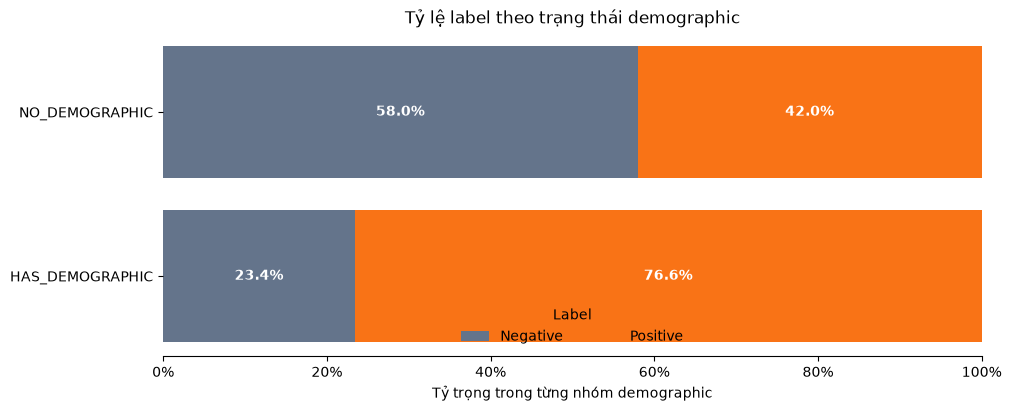

In [5]:
demographic_status_figure = plot_demographic_status_stacked_bar(
    report.demographic_status_summary
)
plt.show()

## 4. Phân phối category trong Positive và Negative

Mỗi màu cộng thành 100% riêng trong label tương ứng. Biểu đồ này trả lời demographic composition của hai lớp khác nhau như thế nào.

In [6]:
report.distribution_summary

,feature,label,label_name,category,n_rows,n_households,within_label_share
0,AGE_DESC,0,Negative,19-24,869,45,0.009165
1,AGE_DESC,0,Negative,25-34,2866,140,0.030225
2,AGE_DESC,0,Negative,35-44,3593,183,0.037892
3,AGE_DESC,0,Negative,45-54,5346,278,0.05638
4,AGE_DESC,0,Negative,55-64,951,58,0.010029
...,...,...,...,...,...,...,...
91,KID_CATEGORY_DESC,1,Positive,1,7045,114,0.065582
92,KID_CATEGORY_DESC,1,Positive,2,3803,60,0.035402
93,KID_CATEGORY_DESC,1,Positive,3+,4127,69,0.038418
94,KID_CATEGORY_DESC,1,Positive,NO_DEMOGRAPHIC_RECORD,57740,1690,0.537501


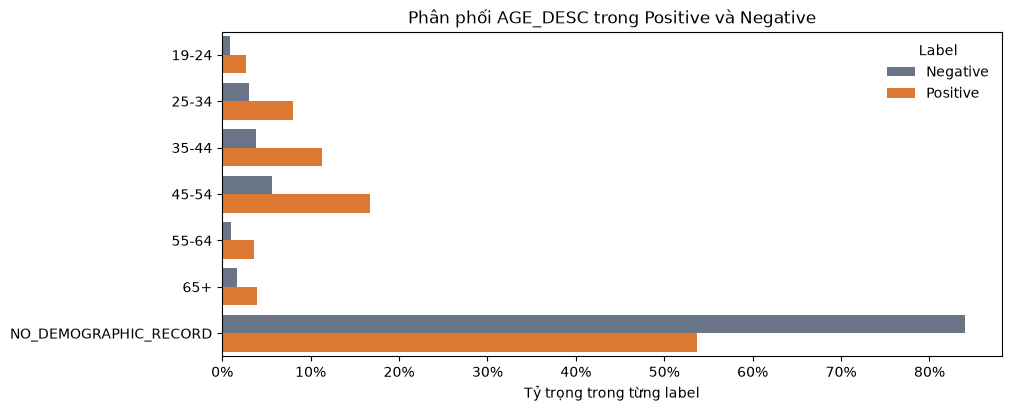

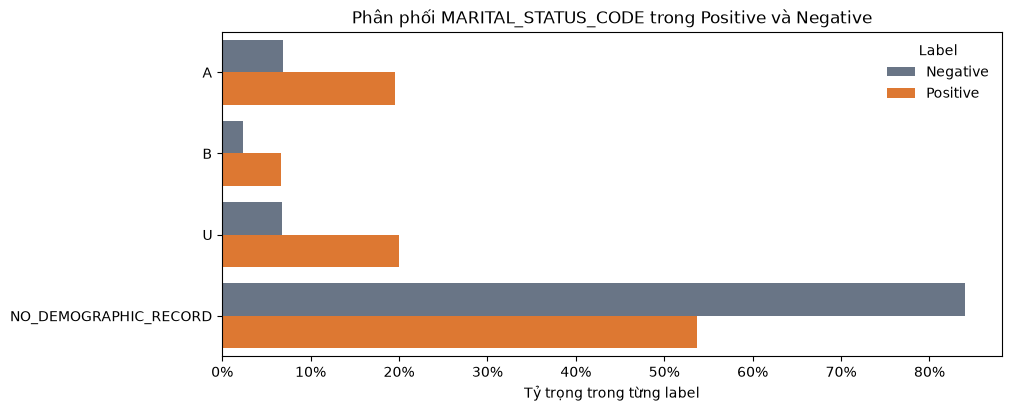

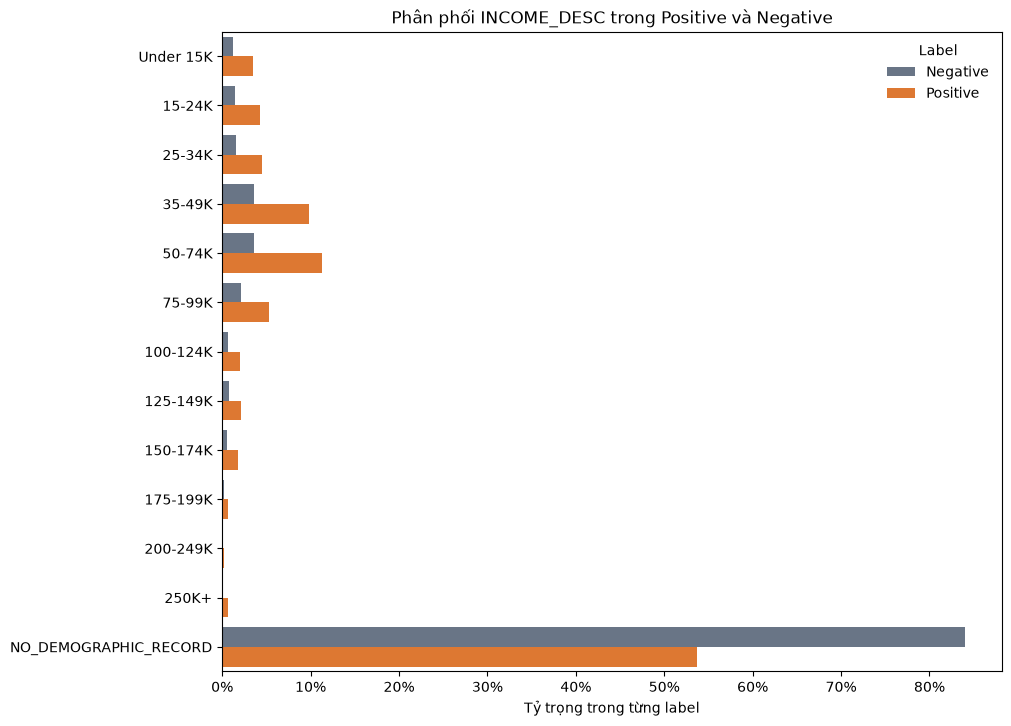

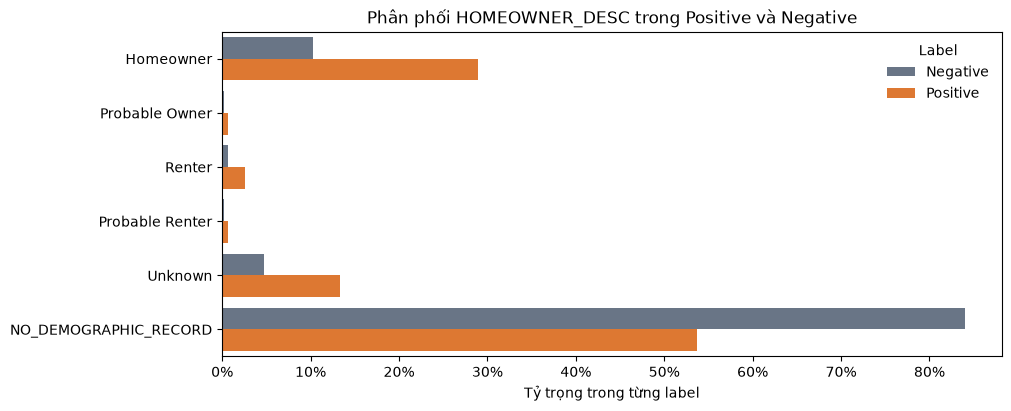

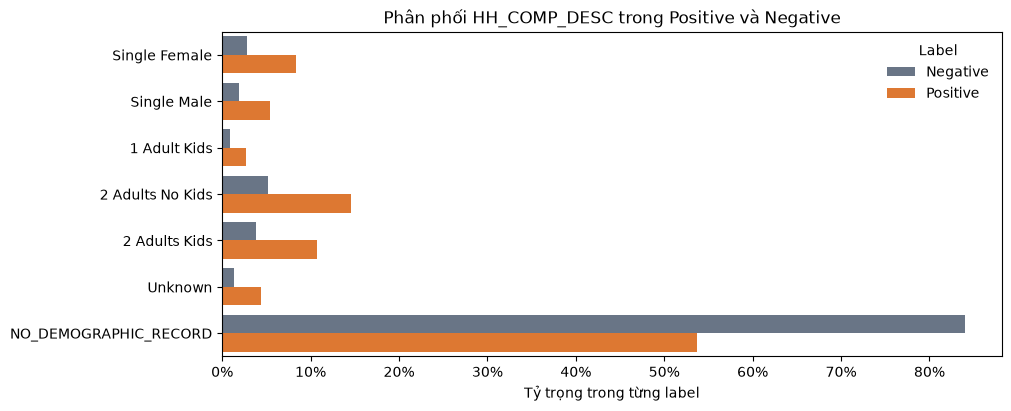

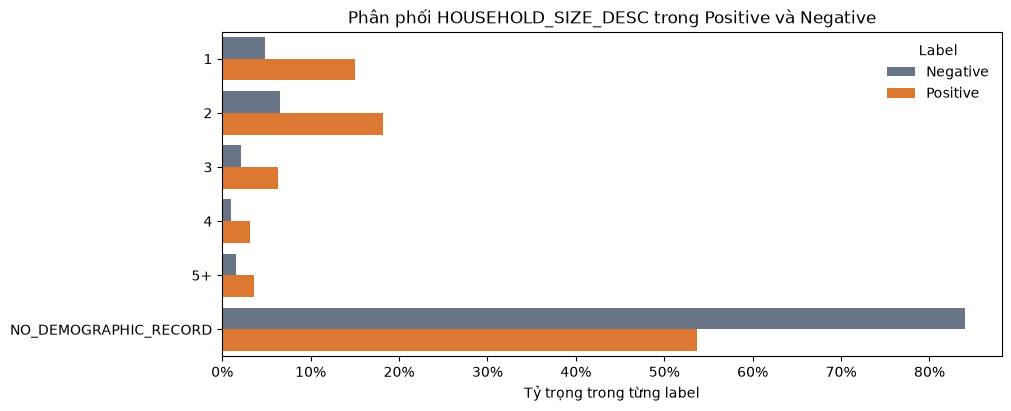

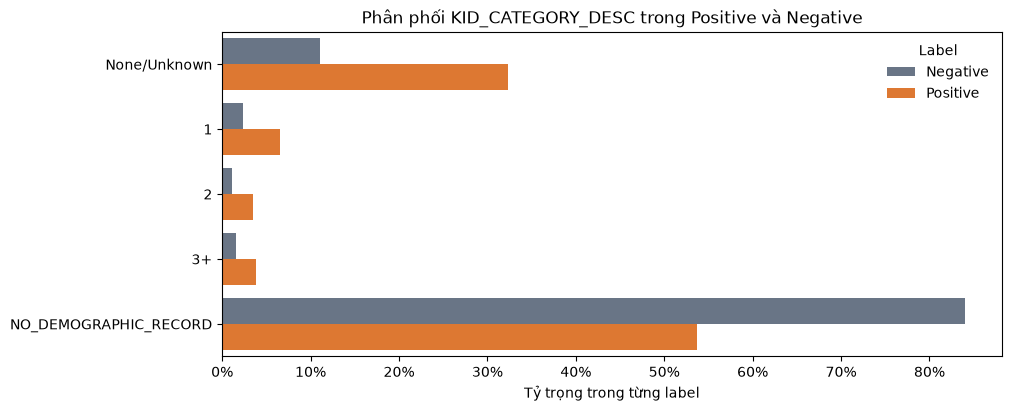

In [7]:
distribution_figures = plot_label_distributions(report.distribution_summary)
plt.show()

## 5. Positive Rate theo từng category

Phần này thay thế box plot. Mỗi category chỉ có một cột ngang biểu diễn:

$$\text{Positive Rate}=\frac{\#(label=1)}{\#(label=0)+\#(label=1)}$$

Đường đỏ nét đứt là positive rate chung của toàn panel. `NO_DEMOGRAPHIC_RECORD` không xuất hiện trong biểu đồ chính vì đây là trạng thái thiếu dữ liệu.

In [8]:
report.positive_rate_summary.sort_values(
    ["feature", "positive_rate"],
    ascending=[True, False],
)

,feature,category,n_observations,n_positive,n_households,n_negative,positive_rate,is_missing_category
4,AGE_DESC,55-64,4779,3828,59,951,0.801004,False
2,AGE_DESC,35-44,15714,12121,194,3593,0.771350,False
3,AGE_DESC,45-54,23328,17982,288,5346,0.770833,False
0,AGE_DESC,19-24,3726,2857,46,869,0.766774,False
1,AGE_DESC,25-34,11502,8636,142,2866,0.750826,False
5,AGE_DESC,65+,5832,4259,72,1573,0.730281,False
6,AGE_DESC,NO_DEMOGRAPHIC_RECORD,137363,57740,1699,79623,0.420346,True
36,HH_COMP_DESC,Unknown,5913,4667,73,1246,0.789278,False
34,HH_COMP_DESC,Single Female,11664,8978,144,2686,0.769719,False
30,HH_COMP_DESC,1 Adult Kids,3807,2928,47,879,0.769110,False


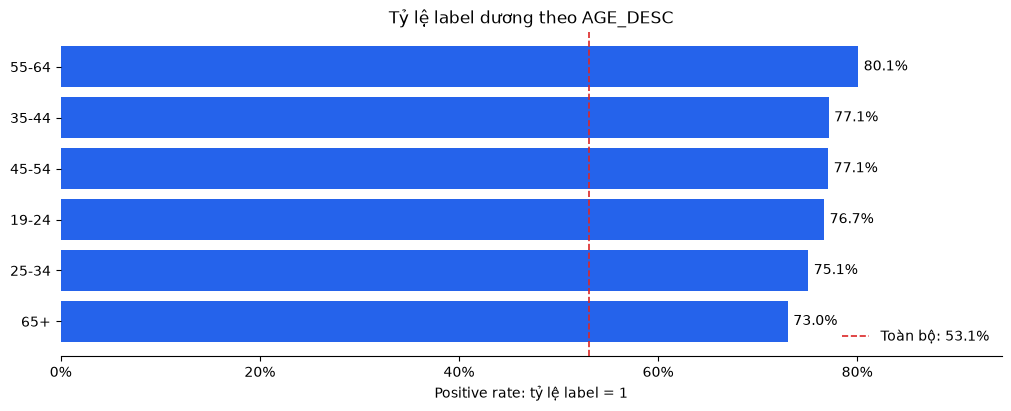

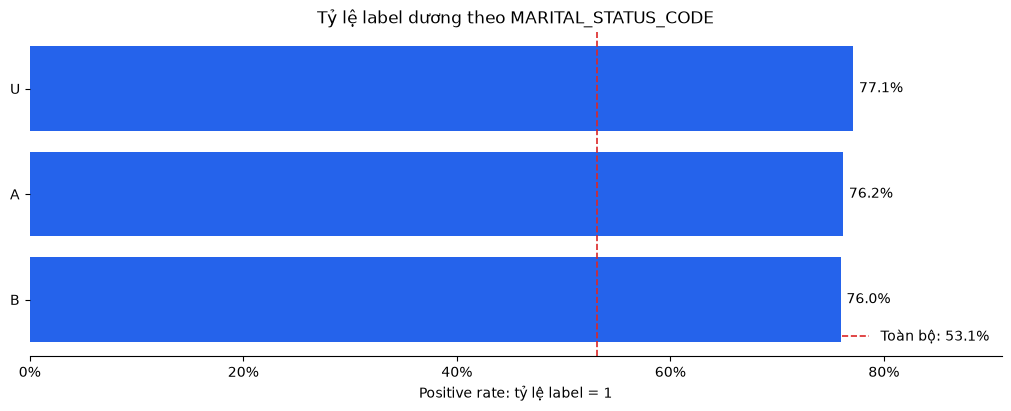

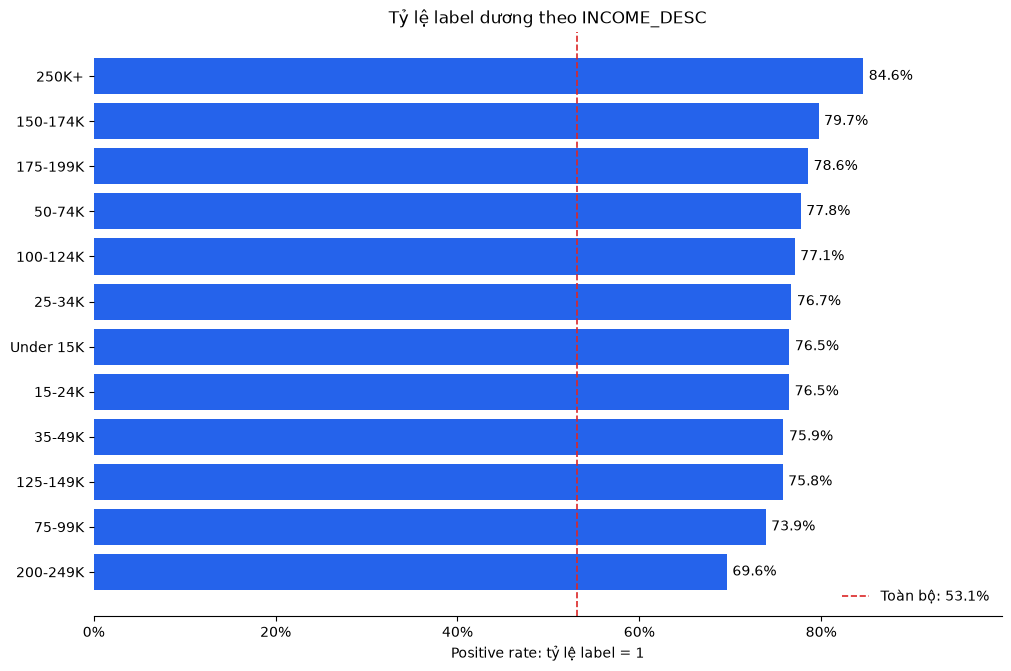

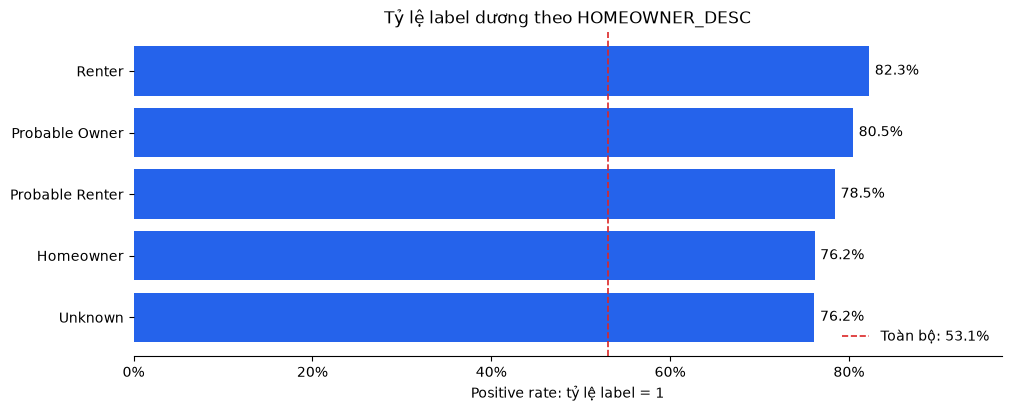

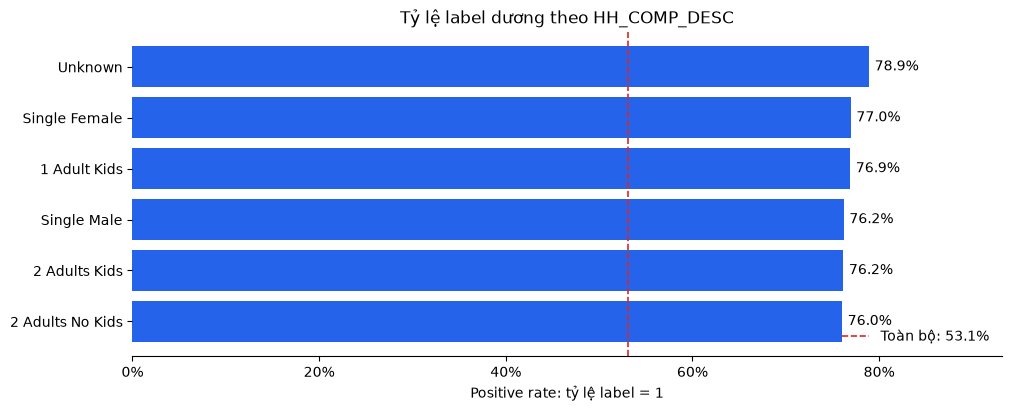

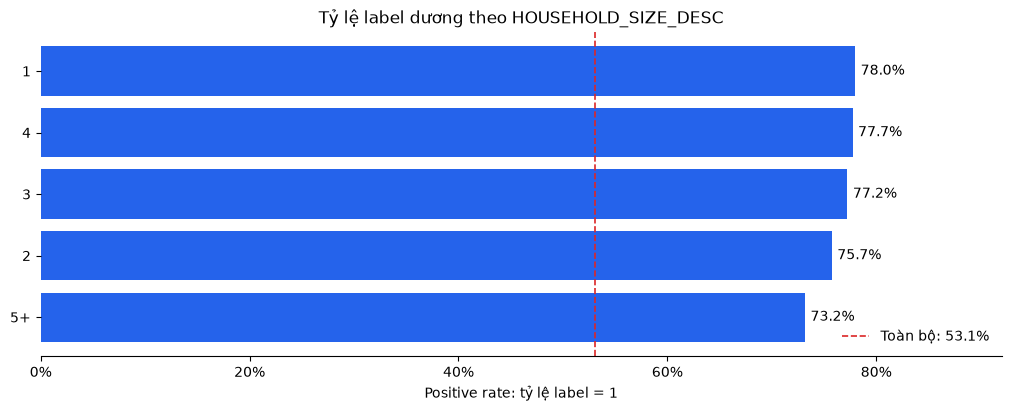

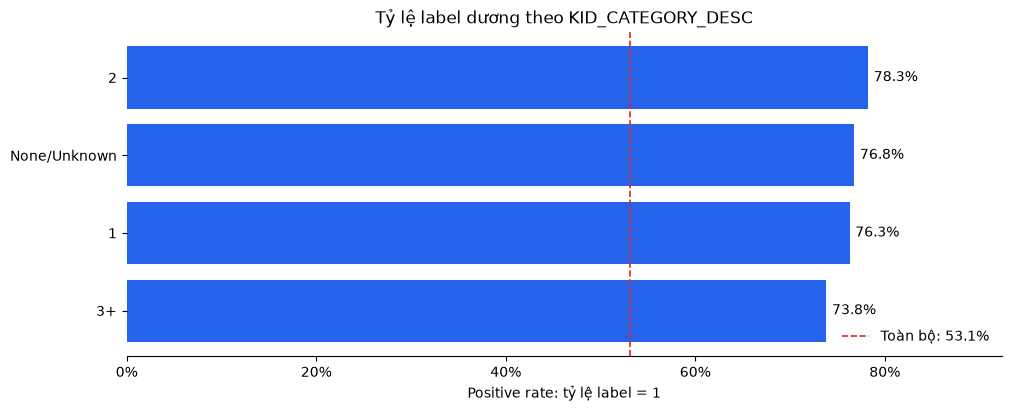

In [9]:
positive_rate_figures = plot_positive_rate_by_category(
    report.positive_rate_summary,
    report.overall_positive_rate,
)
plt.show()

## 6. Household overlap giữa hai label

Demographic là thuộc tính tĩnh nhưng label thay đổi theo cutoff. Bảng này cho biết bao nhiêu household từng xuất hiện ở cả hai label.

In [10]:
report.household_label_overlap

,n_households,n_households_in_both_labels,share_households_in_both_labels
0,2500,2448,0.9792


## 7. Chênh lệch category và khoảng cách phân phối

`positive_minus_negative_pp` dương nghĩa category phổ biến hơn trong Positive; âm nghĩa phổ biến hơn trong Negative. Total-variation distance loại `NO_DEMOGRAPHIC_RECORD` và chuẩn hóa lại trong các dòng có demographic.

In [11]:
report.feature_distance_summary

,feature,total_absolute_gap_pp,total_variation_distance
0,HOUSEHOLD_SIZE_DESC,6.823662,0.034118
1,AGE_DESC,6.506477,0.032532
2,INCOME_DESC,6.387597,0.031938
3,HOMEOWNER_DESC,4.215897,0.021079
4,HH_COMP_DESC,3.404011,0.01702
5,KID_CATEGORY_DESC,3.072666,0.015363
6,MARITAL_STATUS_CODE,2.749302,0.013747


In [12]:
report.category_gap_summary

,feature,category,Negative,Positive,positive_minus_negative_pp,absolute_gap_pp
0,AGE_DESC,65+,0.1035,0.085723,-1.777697,1.777697
1,AGE_DESC,25-34,0.188577,0.173822,-1.475541,1.475541
2,AGE_DESC,55-64,0.062574,0.077048,1.447446,1.447446
3,AGE_DESC,45-54,0.351757,0.361935,1.017786,1.017786
4,AGE_DESC,35-44,0.236413,0.243967,0.755406,0.755406
5,AGE_DESC,19-24,0.057179,0.057505,0.0326,0.0326
6,HH_COMP_DESC,Unknown,0.081984,0.093936,1.195108,1.195108
7,HH_COMP_DESC,2 Adults No Kids,0.325569,0.316144,-0.94248,0.94248
8,HH_COMP_DESC,2 Adults Kids,0.237465,0.232232,-0.52331,0.52331
9,HH_COMP_DESC,Single Female,0.176734,0.180706,0.397189,0.397189


## Lưu ý diễn giải

- Mỗi quan sát là `(household, cutoff)`; một household có thể thuộc cả hai label theo thời gian.
- `n_households` là số household duy nhất đóng góp vào category; positive rate dùng toàn bộ cơ hội dự báo household-cutoff.
- `None/Unknown` không tách được không có trẻ em khỏi không rõ thông tin.
- Code hôn nhân A/B/U không nên tự gán ý nghĩa nếu chưa có data dictionary.
- Parquet label cần được tạo lại sau khi thay đổi target window thành `[cutoff, cutoff+6]`.